In [13]:
# import thu vien
import re
from collections import Counter

import torch
import torch.nn as nn
import pandas as pd
import matplotlib.pyplot as plt

# Tham so gom chung mot cho de chinh
CONFIG = {
    "csv_path": "sentiment_data.csv",
    "seed": 42,          # co dinh de tai lap
    "max_samples": 200000, # lay bot cho nhe (data goc ~241k dong)
    "max_vocab": 10000,    # so tu giu lai trong tu dien
    "seq_len": 30,        # do dai chuoi (so buoc thoi gian T), cat/pad ve day
    "embed_dim": 64,      # so chieu vector nhung tu
    "hidden_size": 128,    # so chieu trang thai an cua LSTM
    "num_classes": 3,     # 3 lop cam xuc: 0, 1, 2
    "batch_size": 64,
    "lr": 0.005,
    "epochs": 10,
    "train_ratio": 0.8,
}

torch.manual_seed(CONFIG["seed"])

In [14]:
# get data len (doc tu file sentiment_data.csv da tai ve)
df = pd.read_csv(CONFIG["csv_path"])

# Chi giu 2 cot can dung: Comment (text) va Sentiment (nhan 0/1/2)
df = df[["Comment", "Sentiment"]].dropna()

# Lay bot cho nhe (xao tron truoc roi cat)
df = df.sample(frac=1.0, random_state=CONFIG["seed"]).reset_index(drop=True)
df = df.iloc[:CONFIG["max_samples"]].reset_index(drop=True)

print("So mau dung:", len(df))
print(df["Sentiment"].value_counts().sort_index())
df.head()

So mau dung: 200000
Sentiment
0    45751
1    68719
2    85530
Name: count, dtype: int64


,Comment,Sentiment
0,indian giving message country going ahead new ...,2
1,hating modi trend loom replies instant famous,2
2,hahaha modi khauff stronger sibling rivalries,2
3,watch official trailer modi subscribe erosnow ...,1
4,called concern poor modi bjp doesnt poor count...,0


In [15]:
# xu ly data de tao data run
# Buoc: tach tu -> xay tu dien -> ma hoa cau thanh day so id -> cat/pad ve seq_len

def tokenize(text):
    # ha chu thuong, chi giu chu va so, tach theo khoang trang
    return re.findall(r"[a-z0-9]+", str(text).lower())

# 1) Xay tu dien tu tap cau, giu lai max_vocab tu hay gap nhat
counter = Counter()
for cmt in df["Comment"]:
    counter.update(tokenize(cmt))

# id 0 = <pad> (dem cho du dai), id 1 = <unk> (tu la khong co trong tu dien)
itos = ["<pad>", "<unk>"] + [w for w, _ in counter.most_common(CONFIG["max_vocab"] - 2)]
stoi = {w: i for i, w in enumerate(itos)}
vocab_size = len(itos)
print("Kich thuoc tu dien:", vocab_size)

# 2) Ma hoa 1 cau thanh day id, cat hoac pad ve dung seq_len
def encode(text, seq_len):
    ids = [stoi.get(tok, 1) for tok in tokenize(text)]  # tu la -> 1 (<unk>)
    ids = ids[:seq_len]                                 # cat neu dai qua
    ids = ids + [0] * (seq_len - len(ids))              # pad 0 neu ngan
    return ids

X = torch.tensor([encode(c, CONFIG["seq_len"]) for c in df["Comment"]], dtype=torch.long)
y = torch.tensor(df["Sentiment"].values, dtype=torch.long)
print("X shape:", X.shape, "| y shape:", y.shape)

# 3) Chia train/test
n_train = int(len(X) * CONFIG["train_ratio"])
X_train, y_train = X[:n_train], y[:n_train]
X_test, y_test = X[n_train:], y[n_train:]
print("Train:", X_train.shape, "| Test:", X_test.shape)

Kich thuoc tu dien: 10000
X shape: torch.Size([200000, 30]) | y shape: torch.Size([200000])
Train: torch.Size([160000, 30]) | Test: torch.Size([40000, 30])


In [16]:
# kiem tra nvidia, gpu
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device dang dung:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device dang dung: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


In [17]:
# class LSTM (from scratch - KHONG dung nn.LSTM)
# Gom TAT CA vao 1 class MyLSTM:
#   - class con Cell: tinh toan node cho 1 buoc thoi gian (tung gate mot)
#   - forward   : cuon Cell qua ca chuoi
#   - accuracy  : do chinh xac
#   - train_step: 1 buoc hoc = forward + backward (autograd lo gradient) + update
#   - evaluate  : chay tren tap test khong tinh gradient
#   - fit       : vong lap huan luyen nhieu epoch, chia batch


class MyLSTM(nn.Module):

    # ---------- class con: tinh toan node cho 1 buoc thoi gian ----------
    class Cell(nn.Module):
        """Mot cell LSTM cho DUY NHAT 1 buoc thoi gian, tinh ro rang tung gate.

        Cong thuc (x_t dau vao, h_{t-1} hidden truoc, c_{t-1} cell truoc):
          f_t = sigmoid(x_t W_f + h_{t-1} U_f + b_f)   forget gate
          i_t = sigmoid(x_t W_i + h_{t-1} U_i + b_i)   input gate
          g_t = tanh   (x_t W_g + h_{t-1} U_g + b_g)   candidate cell
          o_t = sigmoid(x_t W_o + h_{t-1} U_o + b_o)   output gate
          c_t = f_t * c_{t-1} + i_t * g_t              cap nhat cell state
          h_t = o_t * tanh(c_t)                        hidden state moi
        """

        def __init__(self, input_size, hidden_size):
            super().__init__()
            self.hidden_size = hidden_size

            # Trong so tung gate: W_* nhan x_t, U_* nhan h_{t-1}, b_* la bias
            self.W_f = nn.Parameter(torch.empty(input_size, hidden_size))
            self.U_f = nn.Parameter(torch.empty(hidden_size, hidden_size))
            self.b_f = nn.Parameter(torch.zeros(hidden_size))

            self.W_i = nn.Parameter(torch.empty(input_size, hidden_size))
            self.U_i = nn.Parameter(torch.empty(hidden_size, hidden_size))
            self.b_i = nn.Parameter(torch.zeros(hidden_size))

            self.W_g = nn.Parameter(torch.empty(input_size, hidden_size))
            self.U_g = nn.Parameter(torch.empty(hidden_size, hidden_size))
            self.b_g = nn.Parameter(torch.zeros(hidden_size))

            self.W_o = nn.Parameter(torch.empty(input_size, hidden_size))
            self.U_o = nn.Parameter(torch.empty(hidden_size, hidden_size))
            self.b_o = nn.Parameter(torch.zeros(hidden_size))

            # Khoi tao dong deu U(-k, k) voi k = 1/sqrt(hidden_size) (giong pytorch)
            k = 1.0 / (hidden_size ** 0.5)
            for p in self.parameters():
                nn.init.uniform_(p, -k, k)

        def forward(self, x_t, h_prev, c_prev):
            # Tinh tung gate mot
            f_t = torch.sigmoid(x_t @ self.W_f + h_prev @ self.U_f + self.b_f)
            i_t = torch.sigmoid(x_t @ self.W_i + h_prev @ self.U_i + self.b_i)
            g_t = torch.tanh(x_t @ self.W_g + h_prev @ self.U_g + self.b_g)
            o_t = torch.sigmoid(x_t @ self.W_o + h_prev @ self.U_o + self.b_o)

            c_t = f_t * c_prev + i_t * g_t   # cap nhat cell state
            h_t = o_t * torch.tanh(c_t)      # hidden state moi
            return h_t, c_t

    # ---------- class chinh ----------
    def __init__(self, vocab_size, embed_dim, hidden_size, num_classes):
        super().__init__()
        self.hidden_size = hidden_size
        # Embedding: doi id tu -> vector; padding_idx=0 de tu <pad> luon vector 0
        self.embed = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.cell = MyLSTM.Cell(embed_dim, hidden_size)   # class con
        self.fc = nn.Linear(hidden_size, num_classes)     # phan loai tu hidden cuoi

    def forward(self, x):
        # x: (batch, seq_len) cac id tu
        emb = self.embed(x)                 # -> (batch, seq_len, embed_dim)
        batch, seq_len, _ = emb.shape

        # Khoi tao h_0, c_0 = 0
        h_t = torch.zeros(batch, self.hidden_size, device=x.device)
        c_t = torch.zeros(batch, self.hidden_size, device=x.device)

        # Cuon cell qua tung buoc thoi gian
        for t in range(seq_len):
            h_t, c_t = self.cell(emb[:, t, :], h_t, c_t)

        return self.fc(h_t)                 # dung hidden cuoi de phan loai

    # ---------- cac method ho tro hoc ----------
    @staticmethod
    def accuracy(logits, y_true):
        preds = logits.argmax(dim=1)
        return (preds == y_true).float().mean().item()

    def train_step(self, xb, yb, loss_fn, optimizer):
        # 1 buoc hoc: forward -> loss -> backward -> update
        self.train()
        optimizer.zero_grad()
        logits = self(xb)             # forward qua tung gate
        loss = loss_fn(logits, yb)
        loss.backward()               # backward: autograd lan nguoc (BPTT)
        optimizer.step()              # cap nhat trong so
        return loss.item(), self.accuracy(logits, yb)

    @torch.no_grad()
    def evaluate(self, X, y, loss_fn, batch_size):
        # Chay tren tap test theo tung batch (khong tinh gradient)
        self.eval()
        total_loss, total_correct = 0.0, 0
        for i in range(0, len(X), batch_size):
            xb, yb = X[i:i + batch_size], y[i:i + batch_size]
            logits = self(xb)
            total_loss += loss_fn(logits, yb).item() * len(xb)
            total_correct += (logits.argmax(dim=1) == yb).sum().item()
        return total_loss / len(X), total_correct / len(X)

    def fit(self, X_train, y_train, X_test, y_test, cfg, loss_fn, optimizer):
        # Vong lap huan luyen nhieu epoch, moi epoch chia batch va xao tron
        history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
        n = len(X_train)
        for epoch in range(1, cfg["epochs"] + 1):
            perm = torch.randperm(n, device=X_train.device)  # xao tron thu tu
            run_loss, run_correct = 0.0, 0
            for i in range(0, n, cfg["batch_size"]):
                idx = perm[i:i + cfg["batch_size"]]
                xb, yb = X_train[idx], y_train[idx]
                loss, _ = self.train_step(xb, yb, loss_fn, optimizer)
                run_loss += loss * len(xb)
                run_correct += int(self.accuracy(self(xb), yb) * len(xb))

            tr_loss = run_loss / n
            tr_acc = run_correct / n
            te_loss, te_acc = self.evaluate(X_test, y_test, loss_fn, cfg["batch_size"])

            history["train_loss"].append(tr_loss)
            history["train_acc"].append(tr_acc)
            history["test_loss"].append(te_loss)
            history["test_acc"].append(te_acc)
            print(f"Epoch {epoch:2d} | train loss {tr_loss:.4f} acc {tr_acc:.3f} "
                  f"| test loss {te_loss:.4f} acc {te_acc:.3f}")
        return history

In [18]:
# ham ben ngoai: goi den class, truyen data vao de train
# (moi logic hoc nam trong class MyLSTM, o day chi dung + goi)

def run_training(X_train, y_train, X_test, y_test, vocab_size, cfg, device):
    # Dua data len device
    X_train, y_train = X_train.to(device), y_train.to(device)
    X_test, y_test = X_test.to(device), y_test.to(device)

    # Dung model tu class MyLSTM
    model = MyLSTM(
        vocab_size=vocab_size,
        embed_dim=cfg["embed_dim"],
        hidden_size=cfg["hidden_size"],
        num_classes=cfg["num_classes"],
    ).to(device)

    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg["lr"])

    # Goi method fit cua class de huan luyen (co ca forward + backward ben trong)
    history = model.fit(X_train, y_train, X_test, y_test, cfg, loss_fn, optimizer)
    return model, history

In [19]:
# main: trinh tu lam theo de - goi ham train truyen data vao
model, history = run_training(
    X_train, y_train, X_test, y_test,
    vocab_size=vocab_size, cfg=CONFIG, device=device,
)

print("\nDo chinh xac test cuoi cung:", round(history["test_acc"][-1], 3))

Epoch  1 | train loss 0.6516 acc 0.747 | test loss 0.5042 acc 0.811
Epoch  2 | train loss 0.4617 acc 0.842 | test loss 0.4721 acc 0.825
Epoch  3 | train loss 0.4026 acc 0.869 | test loss 0.4633 acc 0.827
Epoch  4 | train loss 0.3568 acc 0.891 | test loss 0.4610 acc 0.834
Epoch  5 | train loss 0.3202 acc 0.909 | test loss 0.4738 acc 0.835
Epoch  6 | train loss 0.2903 acc 0.921 | test loss 0.4814 acc 0.835
Epoch  7 | train loss 0.2701 acc 0.929 | test loss 0.4955 acc 0.833
Epoch  8 | train loss 0.2504 acc 0.936 | test loss 0.5095 acc 0.832
Epoch  9 | train loss 0.2365 acc 0.942 | test loss 0.5159 acc 0.831
Epoch 10 | train loss 0.2275 acc 0.946 | test loss 0.5277 acc 0.833

Do chinh xac test cuoi cung: 0.833


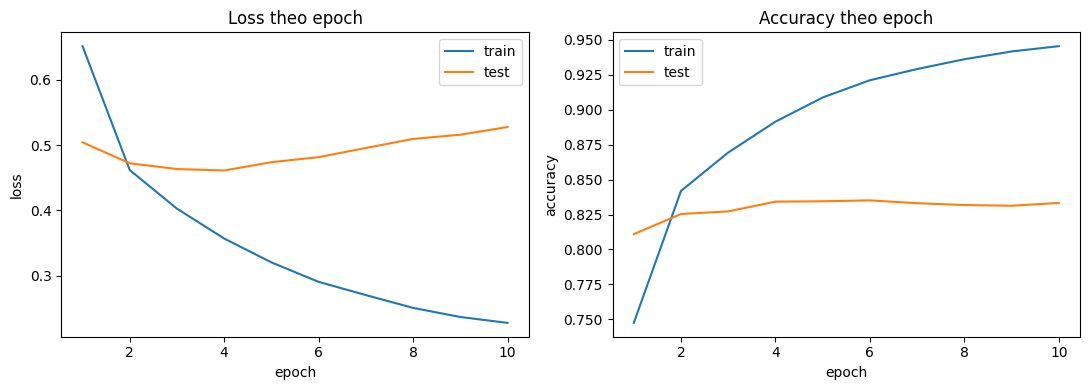

In [20]:
# in / show bieu do: loss va accuracy theo epoch
epochs_axis = range(1, CONFIG["epochs"] + 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(epochs_axis, history["train_loss"], label="train")
axes[0].plot(epochs_axis, history["test_loss"], label="test")
axes[0].set_title("Loss theo epoch")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss")
axes[0].legend()

axes[1].plot(epochs_axis, history["train_acc"], label="train")
axes[1].plot(epochs_axis, history["test_acc"], label="test")
axes[1].set_title("Accuracy theo epoch")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()